In [17]:
from langgraph.graph import StateGraph,START,END

In [18]:
from typing import TypedDict,Annotated,Literal

In [19]:
class eq_state(TypedDict):
    a : int
    b : int
    c : int
    equation : str
    discriminant : float
    result : str

In [20]:
graph = StateGraph(eq_state)

In [21]:
def calculate_d(state : eq_state):
    a = state['a']
    b = state['b']
    c = state['c']
    d = b**2 - (4*a*c)
    return {'discriminant': d}

In [22]:
def show_eq(state : eq_state):
    a = state['a']
    b = state['b']
    c = state['c']
    e = f'{a}x^2+{b}x+{c}'
    return {'equation' : e}

In [23]:
def real_roots(state : eq_state):
    a = state['a']
    b = state['b']
    c = state['c']
    d = state['discriminant']
    r1 = ((-b)+(d**0.5))/(2*a)
    r2 = ((-b)-(d**0.5))/(2*a)
    r = f'the roots are {r1} and {r2}'
    return {'result' : r}

In [24]:
def repeated_roots(state : eq_state):
    a = state['a']
    b = state['b']
    c = state['c']
    d = state['discriminant']
    r1 = (-b)/(2*a)
    r = f'the roots is {r1}'
    return {'result' : r}

In [25]:
def no_roots(state : eq_state):
    r = 'no real root'
    return {'result' : r}

In [26]:
def condition_check(state : eq_state)->Literal['real_roots','repeated_roots','no_roots']:
    d = state['discriminant']
    if d>0:
        return 'real_roots'
    elif d == 0:
        return 'repeated_roots'
    else:
        return 'no_roots'

In [27]:
graph.add_node('calculate_d',calculate_d)
graph.add_node('show_eq',show_eq)
graph.add_node('real_roots',real_roots)
graph.add_node('repeated_roots',repeated_roots)
graph.add_node('no_roots',no_roots)

In [28]:
graph.add_edge(START,'show_eq')
graph.add_edge('show_eq','calculate_d')
graph.add_conditional_edges('calculate_d',condition_check)
graph.add_edge('no_roots',END)
graph.add_edge('repeated_roots',END)
graph.add_edge('real_roots',END)

In [29]:
workflow = graph.compile()

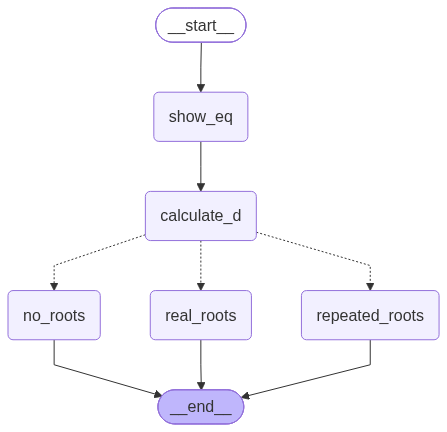

In [30]:
workflow

In [37]:
initial ={
    'a' : 5,
    'b' : 3,
    'c' : 0
}

In [38]:
final = workflow.invoke(initial)

In [39]:
final['result']

'the roots are 0.0 and -0.6'